<a href="https://colab.research.google.com/github/marybello/grb2-KNN-colocalization/blob/main/Grb2_EGFR_KNN_colocalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import xml.etree.ElementTree as ET

In [ ]:
# Function to extract spots data from TrackMate XML
def extract_spots_data(file_path, channel_name):
    tree = ET.parse(file_path)
    root = tree.getroot()
    spots_data = []

    for particle_id, particle in enumerate(root.findall("particle")):
        for detection in particle.findall("detection"):
          frame = int(float(detection.get("t")))
          x = float(detection.get("x"))
          y = float(detection.get("y"))
          spots_data.append({"Particle_ID": particle_id, "Frame": frame, "X": x, "Y": y})


    return spots_data

# Load EGFR and AP-2 data
egfr_file = 'egfr_Tracks.xml'
grb2_file = 'grb2_Tracks.xml'
egfr_data = extract_spots_data(egfr_file, 'EGFR')
grb2_data = extract_spots_data(grb2_file, 'Grb2')
import pandas as pd

# Create DataFrames
egfr_df = pd.DataFrame(egfr_data)
egfr_df['Channel'] = 'EGFR'  # Add channel label for EGFR
grb2_df = pd.DataFrame(grb2_data)
grb2_df['Channel'] = 'Grb2'  # Add channel label for Grb2
# Combine the DataFrames
combined_df = pd.concat([egfr_df, grb2_df])
print(combined_df.head())


   Particle_ID  Frame          X          Y Channel
0            0      0  19.624999  26.388077    EGFR
1            0      1  19.071649  26.189635    EGFR
2            0      2  19.072700  26.379775    EGFR
3            1      0  12.517379  24.799922    EGFR
4            1      1  12.345433  24.590878    EGFR


In [ ]:
from sklearn.neighbors import NearestNeighbors

def analyze_frame_knn(egfr_coords, grb2_coords, distance_threshold=0.4):
    colocalized_grb2 = 0
    avg_colocalized_distance = None
    avg_distance_all = None
    unassociated_egfr = 0
    unique_egfr_colocalized = 0

    if not egfr_coords.empty and not grb2_coords.empty:
        nbrs_egfr = NearestNeighbors(n_neighbors=1).fit(egfr_coords[['X', 'Y']])
        distances_grb2, indices_grb2 = nbrs_egfr.kneighbors(grb2_coords[['X', 'Y']])

        colocalized_mask = distances_grb2 <= distance_threshold
        colocalized_grb2 = colocalized_mask.sum()
        unique_egfr_colocalized = len(set(indices_grb2[colocalized_mask].flatten()))
        avg_distance_all = distances_grb2.mean()

        nbrs_egfr = NearestNeighbors(n_neighbors=1).fit(grb2_coords[['X', 'Y']])
        distances_egfr, _ = nbrs_egfr.kneighbors(egfr_coords[['X', 'Y']])

        if colocalized_grb2 > 0:
            avg_colocalized_distance = distances_grb2[colocalized_mask].mean()

        unassociated_egfr = (distances_egfr > distance_threshold).sum()

    total_egfr_puncta = len(egfr_coords)
    total_grb2_puncta = len(grb2_coords)
    grb2_percentage = (unique_egfr_colocalized / total_egfr_puncta) * 100 if total_egfr_puncta > 0 else 0

    return {
        'Grb2 Colocalized with EGFR (%)': grb2_percentage,
        'Colocalized EGFR Puncta': unique_egfr_colocalized,
        'Colocalized Grb2 Puncta': colocalized_grb2,
        'Avg Colocalized Grb2-EGFR Distance': avg_colocalized_distance,
        'Avg Distance All Grb2-EGFR': avg_distance_all,
        'Unassociated Grb2': total_grb2_puncta - colocalized_grb2,
        'Unassociated EGFR': unassociated_egfr,
        'Total EGFR Puncta': total_egfr_puncta,
        'Total Grb2 Puncta': total_grb2_puncta
    }

In [ ]:
results = []

for frame in sorted(combined_df['Frame'].unique()):
    frame_data = combined_df[combined_df['Frame'] == frame]
    egfr_coords = frame_data[frame_data['Channel'] == 'EGFR'][['X', 'Y']]
    grb2_coords = frame_data[frame_data['Channel'] == 'Grb2'][['X', 'Y']]

    frame_result = analyze_frame_knn(egfr_coords, grb2_coords)
    frame_result['Frame'] = frame
    results.append(frame_result)

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Frame').reset_index(drop=True)

print(results_df)

    Grb2 Colocalized with EGFR (%)  Colocalized EGFR Puncta  \
0                        66.666667                        2   
1                        69.642857                       39   
2                        76.744186                       66   
3                        76.404494                       68   
4                        76.086957                       70   
5                        76.829268                       63   
6                        80.519481                       62   
7                        75.714286                       53   
8                        74.137931                       43   
9                        78.431373                       40   
10                       75.000000                       33   
11                       68.888889                       31   
12                       74.000000                       37   
13                       75.510204                       37   
14                       68.085106                     

In [ ]:
# Make sure results are sorted by frame and time-labeled
frame_to_time = {0: "before"}
frame_to_time.update({i: f"{i-1}min" for i in range(1, 32)})
results_df = results_df.sort_values('Frame').reset_index(drop=True)
results_df['Time'] = results_df['Frame'].map(frame_to_time)

# Normalize colocalized EGFR puncta to Frame 0 (baseline, before ligand)
# Use max(baseline, 1) as a pseudocount in case Frame 0 has 0 colocalized puncta
baseline = results_df.loc[results_df['Frame'] == 0, 'Colocalized EGFR Puncta'].values[0]
baseline = max(baseline, 1)
results_df['Fold Change (vs Frame 0)'] = results_df['Colocalized EGFR Puncta'] / baseline
results_df.to_excel('results.xlsx', index=False)
print(results_df[['Frame', 'Time', 'Colocalized EGFR Puncta', 'Fold Change (vs Frame 0)']])

    Frame    Time  Colocalized EGFR Puncta  Fold Change (vs Frame 0)
0       0  before                        2                       1.0
1       1    0min                       39                      19.5
2       2    1min                       66                      33.0
3       3    2min                       68                      34.0
4       4    3min                       70                      35.0
5       5    4min                       63                      31.5
6       6    5min                       62                      31.0
7       7    6min                       53                      26.5
8       8    7min                       43                      21.5
9       9    8min                       40                      20.0
10     10    9min                       33                      16.5
11     11   10min                       31                      15.5
12     12   11min                       37                      18.5
13     13   12min                 

In [ ]:
baseline_raw = results_df.loc[results_df['Frame'] == 0, 'Colocalized EGFR Puncta'].values[0]
print(f"Raw Frame 0 colocalized count: {baseline_raw}")

Raw Frame 0 colocalized count: 41


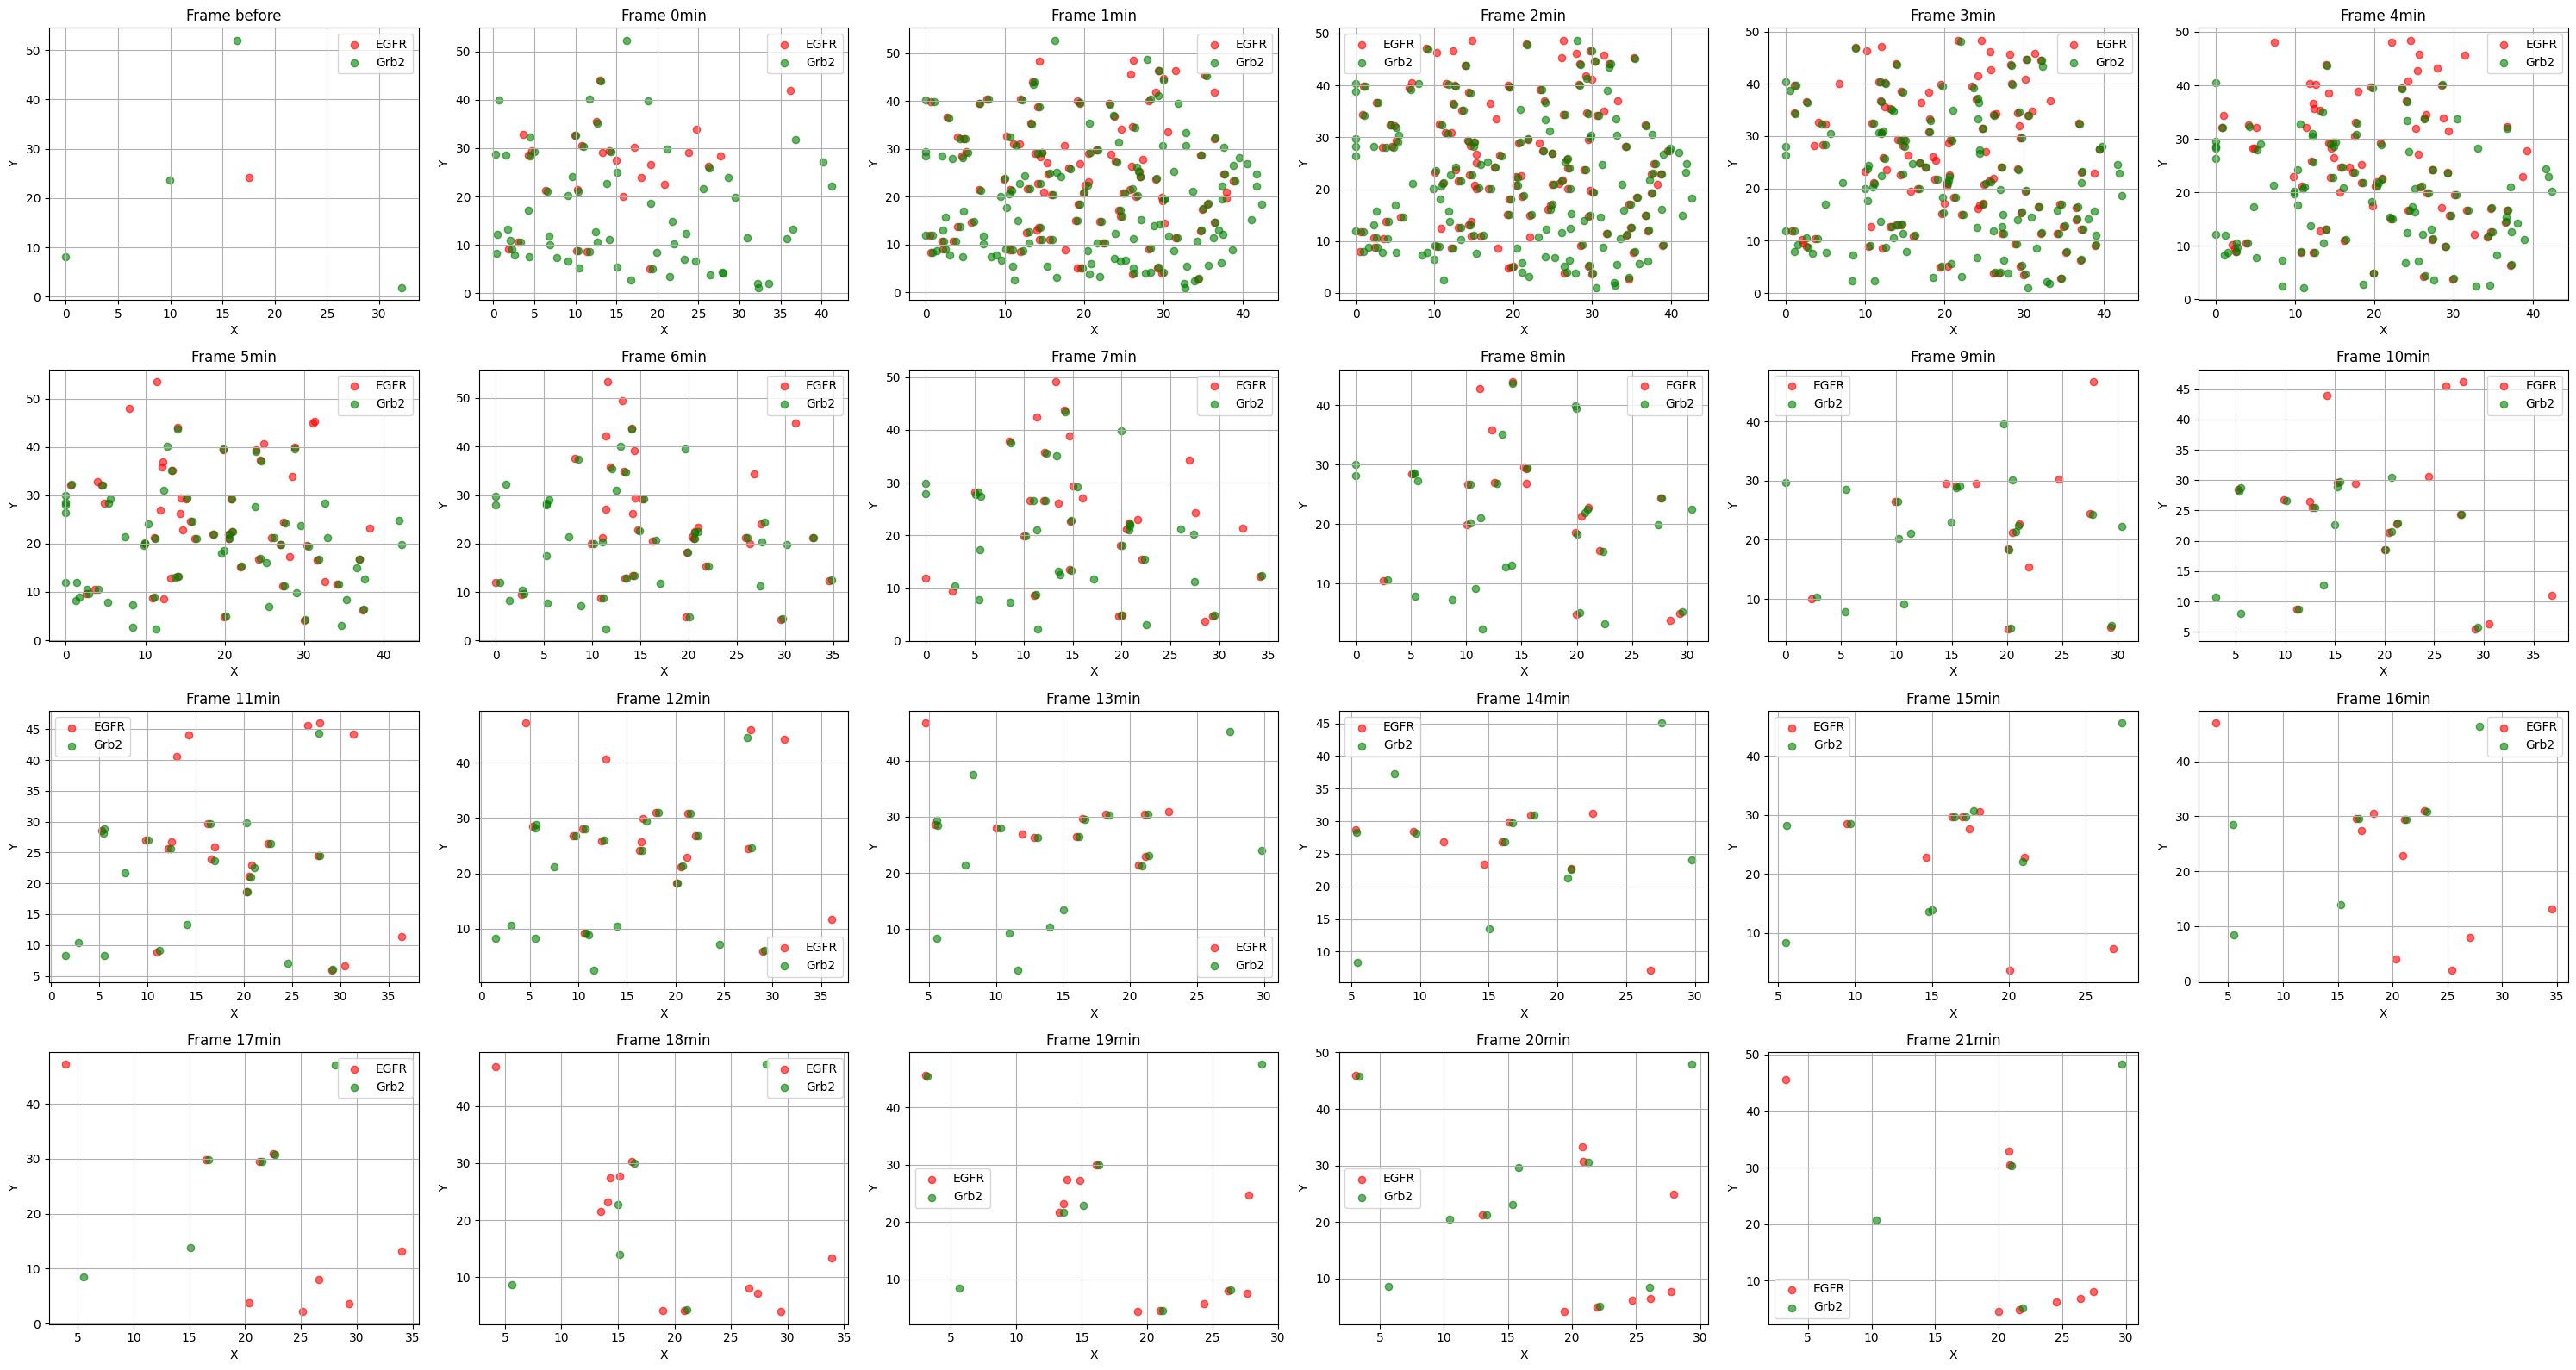

In [ ]:
import matplotlib.pyplot as plt
import math

# Map frames to time points
# Frame 0 = before ligand addition
# Frames 1-31 = 0min through 30min post-ligand (1 frame per minute)
frame_to_time = {0: "before"}
frame_to_time.update({i: f"{i-1}min" for i in range(1, 32)})

# Get the list of unique frames and sort them
unique_frames = sorted(combined_df['Frame'].unique())  # Ensure frames are sorted numerically

# Determine the number of rows and columns for subplots
num_frames = len(unique_frames)
num_cols = 6
num_rows = math.ceil(num_frames / num_cols)

# Create a figure with subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 4))
axes = axes.flatten()  # Flatten axes array for easier indexing

# Iterate over each frame and create a subplot
for i, frame in enumerate(unique_frames):
    # Filter data for the current frame
    frame_data = combined_df[combined_df['Frame'] == frame]
    egfr_coords = frame_data[frame_data['Channel'] == 'EGFR'][['X', 'Y']]
    grb2_coords = frame_data[frame_data['Channel'] == 'Grb2'][['X', 'Y']]

    # Plot EGFR and Grb2 puncta in the current subplot
    # Note: EGFR is now the RED channel and Grb2 is now the GREEN channel (swapped vs. the AP-2 experiments)
    axes[i].scatter(egfr_coords['X'], egfr_coords['Y'], label='EGFR', color='red', alpha=0.6)
    axes[i].scatter(grb2_coords['X'], grb2_coords['Y'], label='Grb2', color='green', alpha=0.6)
    axes[i].set_title(f"Frame {frame_to_time.get(frame, f'Frame {frame}')}")
    axes[i].set_xlabel("X")
    axes[i].set_ylabel("Y")
    axes[i].legend()
    axes[i].grid(True)

# Hide unused subplots if the total number of frames is less than the grid size
for j in range(num_frames, len(axes)):
    axes[j].axis('off')

# Adjust layout
plt.tight_layout()
plt.show()

In [ ]:
results = []

# Loop through all frames IN NUMERIC ORDER (this was the bug — .unique() alone doesn't sort)
for frame in sorted(combined_df['Frame'].unique()):
    # Filter data for the current frame
    frame_data = combined_df[combined_df['Frame'] == frame]
    egfr_coords = frame_data[frame_data['Channel'] == 'EGFR'][['X', 'Y']]
    grb2_coords = frame_data[frame_data['Channel'] == 'Grb2'][['X', 'Y']]

    # Perform KNN colocalization analysis
    frame_result = analyze_frame_knn(egfr_coords, grb2_coords)
    frame_result['Frame'] = frame
    results.append(frame_result)

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

# Belt-and-suspenders: sort by Frame explicitly in case anything upstream changes
results_df = results_df.sort_values('Frame').reset_index(drop=True)

# Display the results
print(results_df)
results_df.to_excel('results.xlsx', index=False)

    Grb2 Colocalized with EGFR (%)  Avg Colocalized Grb2-EGFR Distance  \
0                         0.000000                                 NaN   
1                        76.923077                            0.146173   
2                        83.916084                            0.128327   
3                        81.283422                            0.129431   
4                        89.285714                            0.123121   
5                        84.337349                            0.131435   
6                        86.614173                            0.140701   
7                        92.000000                            0.137628   
8                        93.023256                            0.141755   
9                        77.777778                            0.123377   
10                       74.545455                            0.132428   
11                       69.230769                            0.140092   
12                       60.526316    

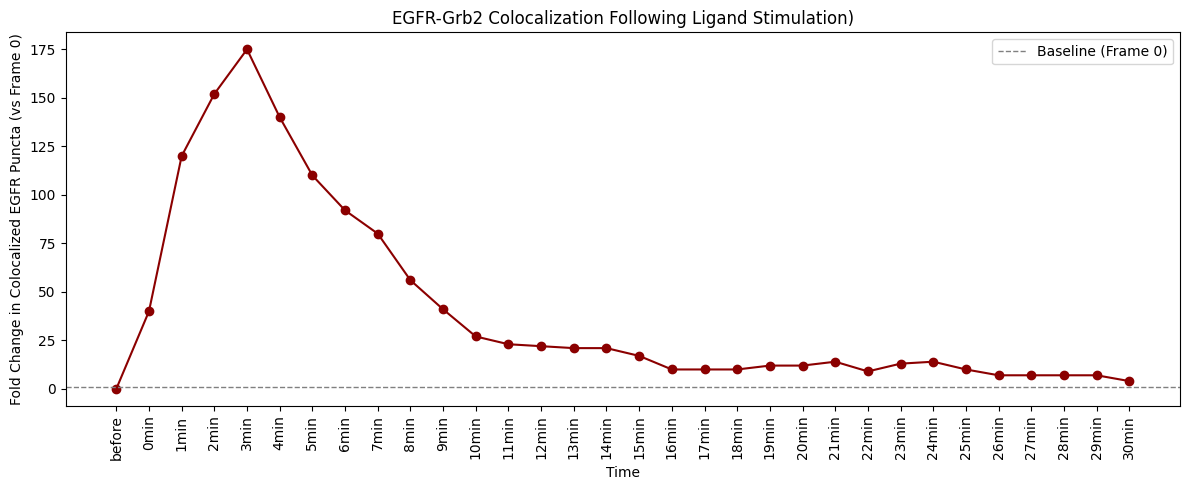

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(results_df['Time'], results_df['Fold Change (vs Frame 0)'], marker='o', color='darkred')
ax.axhline(1, color='gray', linestyle='--', linewidth=1, label='Baseline (Frame 0)')
ax.set_xlabel('Time')
ax.set_ylabel('Fold Change in Colocalized EGFR Puncta (vs Frame 0)')
ax.set_title('EGFR-Grb2 Colocalization Following Ligand Stimulation)')
plt.xticks(rotation=90)
ax.legend()
plt.tight_layout()
plt.show()